# Phase 3: Exploratory Data Analysis (EDA)

Quick exploratory pass on our clean Telco data (`customer_churn_clean.csv`) to understand churn distribution and key drivers (contracts, pricing, tenure) before diving into statistical testing.

In [1]:
import os
print(os.getcwd())

C:\Users\HP\Desktop\Customer-Churn-Analytics\notebooks


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Basic plot styling
sns.set_theme(style="ticks")
plt.rcParams['figure.figsize'] = (10, 5)

# Load clean data
df = pd.read_csv("../data/Processed/customer_churn_clean.csv")
df.head()

,customerid,count,country,state,city,zip_code,lat_long,latitude,longitude,gender,...,contract,paperless_billing,payment_method,monthly_charges,total_charges,churn_label,churn_value,churn_score,cltv,churn_reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.50,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30,Yes,1,89,5340,Competitor had better devices


### 1. Target Variable: How high is overall churn?

Churn Counts:
 churn_label
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentage:
 churn_label
No     73.46
Yes    26.54
Name: proportion, dtype: float64


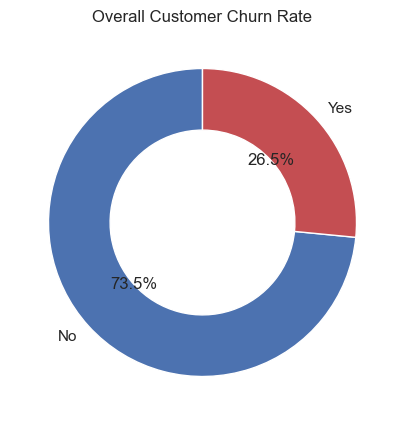

In [5]:
# Check target column name dynamically
target_col = 'churn_label' if 'churn_label' in df.columns else 'churn'

churn_counts = df[target_col].value_counts()
churn_pct = df[target_col].value_counts(normalize=True) * 100

print("Churn Counts:\n", churn_counts)
print("\nChurn Percentage:\n", churn_pct.round(2))

# Quick donut chart for visual baseline
fig, ax = plt.subplots(figsize=(6, 5))
colors = ['#4c72b0', '#c44e52']
ax.pie(churn_counts, labels=churn_counts.index, autopct='%1.1f%%', startangle=90, colors=colors, wedgeprops=dict(width=0.4))
ax.set_title("Overall Customer Churn Rate")
plt.show()

### 2. Contract Types & Payment Methods vs Churn

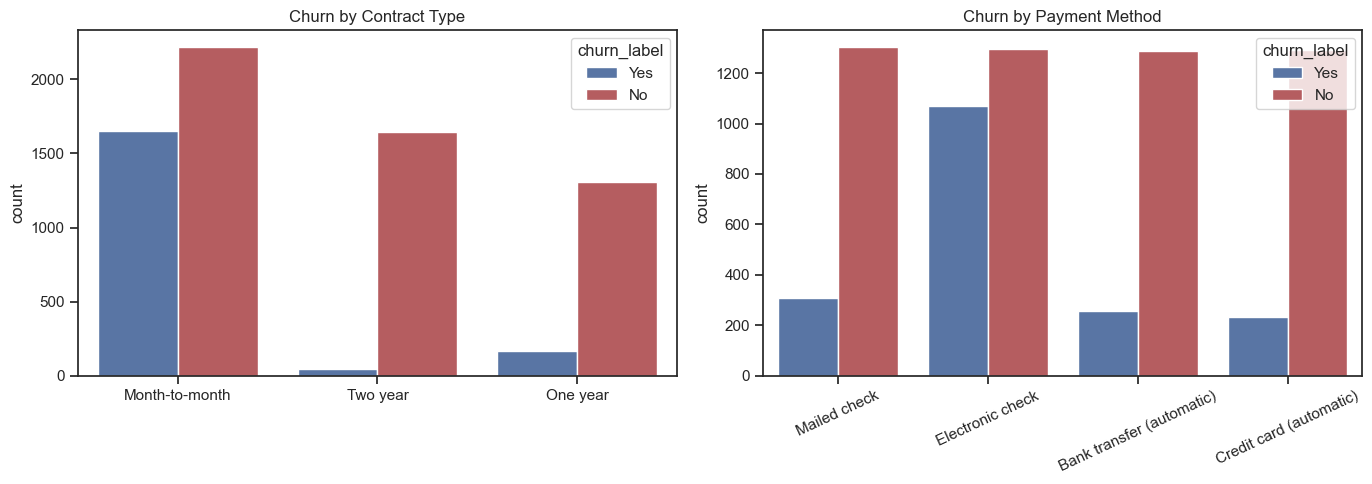

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Contract breakdown
sns.countplot(data=df, x='contract', hue=target_col, ax=axes[0], palette=['#4c72b0', '#c44e52'])
axes[0].set_title("Churn by Contract Type")
axes[0].set_xlabel("")

# Payment method breakdown
sns.countplot(data=df, x='payment_method', hue=target_col, ax=axes[1], palette=['#4c72b0', '#c44e52'])
axes[1].set_title("Churn by Payment Method")
axes[1].set_xlabel("")
axes[1].tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.show()

### 3. Numerical Drivers: Tenure & Monthly Charges

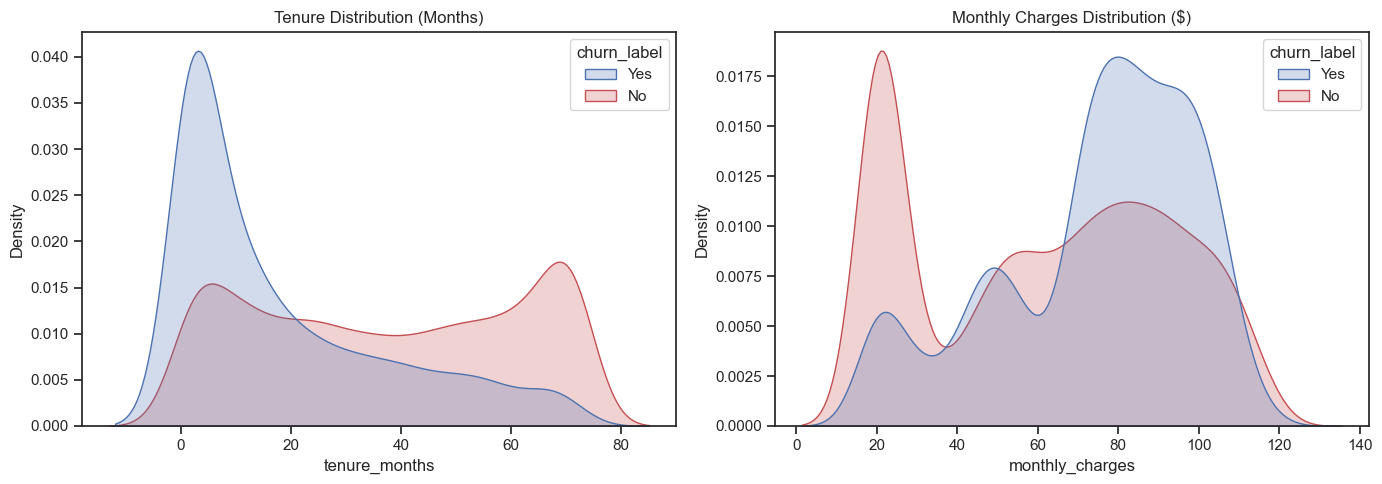

In [9]:
tenure_col = 'tenure_months' if 'tenure_months' in df.columns else 'tenure'

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Tenure distribution
sns.kdeplot(data=df, x=tenure_col, hue=target_col, fill=True, ax=axes[0], palette=['#4c72b0', '#c44e52'], common_norm=False)
axes[0].set_title("Tenure Distribution (Months)")

# Monthly charges distribution
sns.kdeplot(data=df, x='monthly_charges', hue=target_col, fill=True, ax=axes[1], palette=['#4c72b0', '#c44e52'], common_norm=False)
axes[1].set_title("Monthly Charges Distribution ($)")

plt.tight_layout()
plt.show()

### 4. Correlation Matrix

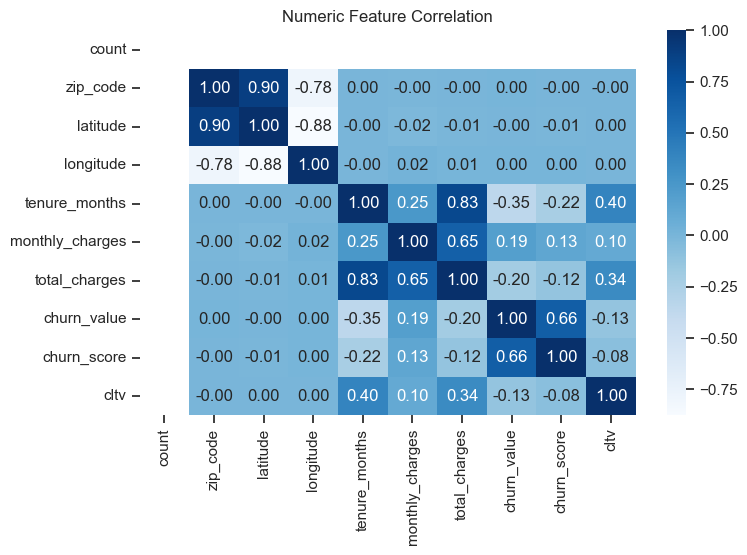

In [10]:
# Quick correlation map for numeric columns
numeric_cols = df.select_dtypes(include=[np.number])

plt.figure(figsize=(8, 5))
sns.heatmap(numeric_cols.corr(), annot=True, fmt=".2f", cmap="Blues")
plt.title("Numeric Feature Correlation")
plt.savefig("../images/feature_importance.png", dpi=300, bbox_inches='tight')
plt.show()